# Proyek Analisis Data: Penjualan Produk E-Commerce
- **Nama:** Jeremy Tjahjana
- **Email:** jeremytjahjana@gmail.com
- **ID Dicoding:** Jeremy Tjahjana 

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren bulanan nilai penjualan produk dari Januari 2017 hingga Januari 2018?
- **Pertanyaan 2:** Kategori produk apa yang menyumbang nilai penjualan produk terbesar selama Januari 2017 sampai Januari 2018?


## Import Semua Packages/Library yang Digunakan

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load seluruh dataset

In [39]:
customers_df = pd.read_csv("data/customers_dataset.csv")
customers_df.info()

print("\nJumlah nilai yang hilang:\n", customers_df.isna().sum())
print("\nJumlah baris yang duplikat:", customers_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB

Jumlah nilai yang hilang:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Jumlah baris yang duplikat: 0


In [40]:
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
geolocation_df.info()

print("\nJumlah nilai yang hilang:\n", geolocation_df.isna().sum())
print("\nJumlah baris yang duplikat:", geolocation_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB

Jumlah nilai yang hilang:
 geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Jumlah baris yang duplikat: 261831


In [41]:
order_items = pd.read_csv("data/order_items_dataset.csv")
order_items.info()

print("\nJumlah nilai yang hilang:\n", order_items.isna().sum())
print("\nJumlah baris yang duplikat:", order_items.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB

Jumlah nilai yang hilang:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Jumlah baris yang duplikat: 0


In [42]:
order_payments = pd.read_csv("data/order_payments_dataset.csv")
order_payments.info()

print("\nJumlah nilai yang hilang:\n", order_payments.isna().sum())
print("\nJumlah baris yang duplikat:", order_payments.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB

Jumlah nilai yang hilang:
 order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Jumlah baris yang duplikat: 0


In [43]:
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
order_reviews_df.info()

print("\nJumlah nilai yang hilang:\n", order_reviews_df.isna().sum())
print("\nJumlah baris yang duplikat:", order_reviews_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB

Jumlah nilai yang hilang:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Jumlah baris yang duplikat: 0


In [44]:
orders_dataset_df = pd.read_csv("data/orders_dataset.csv")
orders_dataset_df.info()

print("\nJumlah nilai yang hilang:\n", orders_dataset_df.isna().sum())
print("\nJumlah baris yang duplikat:", orders_dataset_df.duplicated().sum())

print("\nDelivered tetapi tidak memiliki tanggal pengiriman:", orders_dataset_df.loc[
    (orders_dataset_df["order_status"] == "delivered")
    & (orders_dataset_df["order_delivered_customer_date"].isna())
].shape[0])


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

Jumlah nilai yang hilang:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date 

In [45]:
products_category_name_translation_df = pd.read_csv("data/product_category_name_translation.csv")
products_category_name_translation_df.info()

print("\nJumlah nilai yang hilang:\n", products_category_name_translation_df.isna().sum())
print("\nJumlah baris yang duplikat:", products_category_name_translation_df.duplicated().sum())    

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 3.5 KB

Jumlah nilai yang hilang:
 product_category_name            0
product_category_name_english    0
dtype: int64

Jumlah baris yang duplikat: 0


In [46]:
products_dataset_df = pd.read_csv("data/products_dataset.csv")
products_dataset_df.info()

print("\nJumlah nilai yang hilang:\n", products_dataset_df.isna().sum())
print("\nJumlah baris yang duplikat:", products_dataset_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB

Jumlah nilai yang hilang:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g              

In [47]:
seller_df = pd.read_csv("data/sellers_dataset.csv")
seller_df.info()

print("\nJumlah nilai yang hilang:\n", seller_df.isna().sum())
print("\nJumlah baris yang duplikat:", seller_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB

Jumlah nilai yang hilang:
 seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Jumlah baris yang duplikat: 0


**Insight:** (Opsional)
- Fokus untuk menjawab pertanyaan akan ada pada kolom-kolom "order" dan "product" -> produk apa, kapan, dan total.
- Kolom tanggal-tanggal masih belum diubah ke datetime.

### Assessing Data

#### Identifying data quality problem

In [48]:
print("Tipe data tanggal pembelian:", orders_dataset_df["order_purchase_timestamp"].dtype)
print("Pesanan bukan delivered:", orders_dataset_df["order_status"].ne("delivered").sum())
print("Pesanan delivered tanpa tanggal diterima pelanggan:",
      ((orders_dataset_df["order_status"] == "delivered")
       & orders_dataset_df["order_delivered_customer_date"].isna()).sum())
print("Produk tanpa kategori:", products_dataset_df["product_category_name"].isna().sum())
print("Kategori tanpa terjemahan:", sorted(
    set(products_dataset_df["product_category_name"].dropna())
    - set(products_category_name_translation_df["product_category_name"])
))


Tipe data tanggal pembelian: str
Pesanan bukan delivered: 2963
Pesanan delivered tanpa tanggal diterima pelanggan: 8
Produk tanpa kategori: 610
Kategori tanpa terjemahan: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


**Steps to Take:**
- Ubah tanggal pembelian menjadi datetime dan gunakan pesanan `delivered` untuk analisis penjualan.
- Isi kategori kosong dengan `unknown`; gunakan nama asli jika terjemahan tidak tersedia.

**Insight:** (Opsional)
- Tanggal pembelian masih berupa teks; ada 2.963 pesanan selain `delivered` dan 8 pesanan `delivered` tanpa tanggal diterima pelanggan.
- Ada 610 produk tanpa kategori, 2 kategori tanpa terjemahan, dan 261.831 baris geolocation identik.

### Cleaning Data

#### Fixing data type and missing category problem

In [49]:
orders_dataset_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_dataset_df["order_purchase_timestamp"]
)
products_dataset_df["product_category_name"] = products_dataset_df[
    "product_category_name"
].fillna("unknown")
category_translation = products_category_name_translation_df.set_index(
    "product_category_name"
)["product_category_name_english"]
products_dataset_df["category_name"] = products_dataset_df[
    "product_category_name"
].map(category_translation).fillna(products_dataset_df["product_category_name"])

print("Tipe tanggal pembelian:", orders_dataset_df["order_purchase_timestamp"].dtype)
print("Kategori produk kosong:", products_dataset_df["category_name"].isna().sum())

Tipe tanggal pembelian: datetime64[us]
Kategori produk kosong: 0


**Insight:** (Opsional)
- Tanggal pembelian telah menjadi datetime; 8 pesanan tanpa tanggal diterima tetap dipertahankan karena analisis memakai tanggal pembelian.
- Kategori kosong menjadi `unknown`, sedangkan kategori tanpa terjemahan memakai nama asli. Geolocation tidak diubah karena tidak digunakan.

## Exploratory Data Analysis (EDA)

### Explore monthly sales and product categories

In [50]:
selected_orders = orders_dataset_df.loc[
    orders_dataset_df["order_status"].eq("delivered")
    & orders_dataset_df["order_purchase_timestamp"].ge("2017-01-01")
    & orders_dataset_df["order_purchase_timestamp"].lt("2018-02-01"),
    ["order_id", "order_purchase_timestamp"],
]
sales_df = order_items.merge(selected_orders, on="order_id").merge(
    products_dataset_df[["product_id", "category_name"]], on="product_id"
)
sales_df["month"] = sales_df["order_purchase_timestamp"].dt.to_period("M")
monthly_sales_df = sales_df.groupby("month", as_index=False)["price"].sum()
category_sales_df = sales_df.groupby("category_name", as_index=False)["price"].sum()
category_sales_df = category_sales_df.sort_values("price", ascending=False)

print("Nilai penjualan bulanan (tanpa ongkos kirim):")
print(monthly_sales_df.to_string(index=False))
print("\n10 kategori dengan nilai penjualan terbesar:")
print(category_sales_df.head(10).to_string(index=False))

Nilai penjualan bulanan (tanpa ongkos kirim):
  month     price
2017-01 111798.36
2017-02 234223.40
2017-03 359198.85
2017-04 340669.68
2017-05 489338.25
2017-06 421923.37
2017-07 481604.52
2017-08 554699.70
2017-09 607399.67
2017-10 648247.65
2017-11 987765.37
2017-12 726033.19
2018-01 924645.00

10 kategori dengan nilai penjualan terbesar:
        category_name     price
       bed_bath_table 566005.05
        watches_gifts 549131.95
        health_beauty 545238.60
       sports_leisure 521846.97
computers_accessories 472290.16
           cool_stuff 420356.71
      furniture_decor 378386.41
                 toys 320439.56
         garden_tools 283742.26
                 auto 270405.11


**Insight:** (Opsional)
- Nilai penjualan bulanan naik dari 111.798,36 pada Januari 2017 menjadi 924.645,00 pada Januari 2018; nilai tertinggi terjadi pada November 2017 (987.765,37).
- `bed_bath_table` menyumbang nilai penjualan terbesar, yaitu 566.005,05, selama periode analisis.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren bulanan nilai penjualan produk dari Januari 2017 hingga Januari 2018?

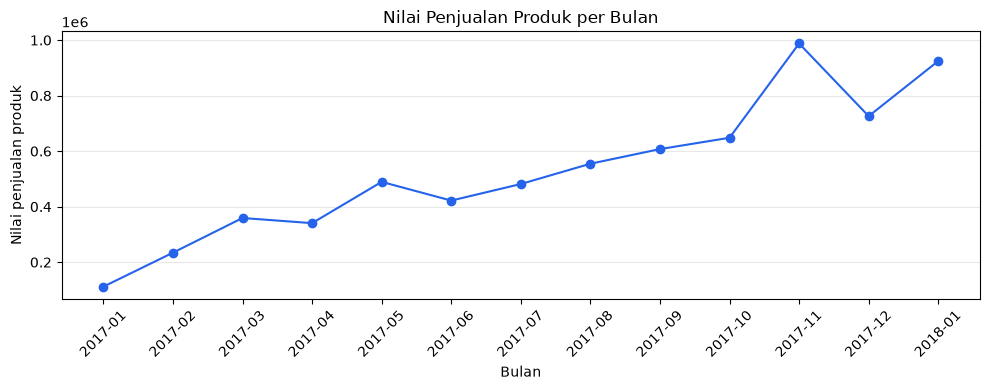

In [51]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_sales_df["month"].astype(str), monthly_sales_df["price"],
        marker="o", color="#2563eb")
ax.set(title="Nilai Penjualan Produk per Bulan", xlabel="Bulan",
       ylabel="Nilai penjualan produk")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

### Pertanyaan 2: Kategori produk apa yang menyumbang nilai penjualan produk terbesar selama Januari 2017 hingga Januari 2018?

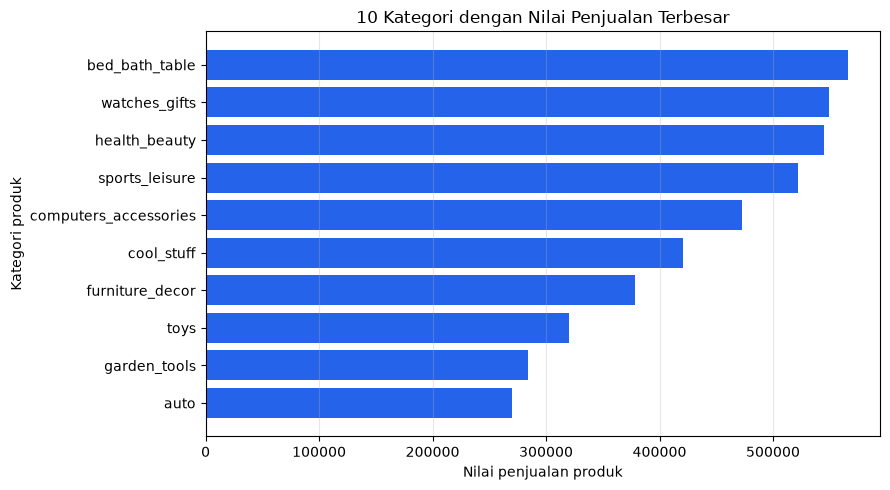

In [52]:
top_categories = category_sales_df.head(10).sort_values("price")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_categories["category_name"], top_categories["price"], color="#2563eb")
ax.set(title="10 Kategori dengan Nilai Penjualan Terbesar",
       xlabel="Nilai penjualan produk", ylabel="Kategori produk")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Insight:** (Opsional)
- Nilai penjualan tertinggi terjadi pada November 2017 (987.765,37), lalu turun 26,5% pada Desember 2017.
- `bed_bath_table` menjadi kategori terbesar dengan nilai penjualan 566.005,05, sekitar 8,2% dari total periode analisis.

## Analisis Lanjutan (Opsional)

In [53]:
monthly_growth_df = monthly_sales_df.copy()
monthly_growth_df["growth_pct"] = (monthly_growth_df["price"].pct_change() * 100).round(1)
top3_share = category_sales_df.head(3)["price"].sum() / category_sales_df["price"].sum() * 100
print("Perubahan nilai penjualan dari bulan sebelumnya (%):")
print(monthly_growth_df[["month", "growth_pct"]].to_string(index=False))
print(f"\nKontribusi tiga kategori terbesar: {top3_share:.1f}%")

Perubahan nilai penjualan dari bulan sebelumnya (%):
  month  growth_pct
2017-01         NaN
2017-02       109.5
2017-03        53.4
2017-04        -5.2
2017-05        43.6
2017-06       -13.8
2017-07        14.1
2017-08        15.2
2017-09         9.5
2017-10         6.7
2017-11        52.4
2017-12       -26.5
2018-01        27.4

Kontribusi tiga kategori terbesar: 24.1%


**Insight:** (Opsional)
- Penurunan bulanan terbesar terjadi dari November ke Desember 2017 (-26,5%); nilai penjualan naik lagi 27,4% pada Januari 2018.
- Tiga kategori teratas menyumbang 24,1% dari total nilai penjualan selama periode analisis.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Nilai penjualan produk cenderung meningkat dari 111.798,36 pada Januari 2017 menjadi 924.645,00 pada Januari 2018, meskipun naik turun. Puncaknya terjadi pada November 2017 (987.765,37).
- **Conclusion pertanyaan 2:** `bed_bath_table` menyumbang nilai penjualan terbesar (566.005,05), diikuti `watches_gifts` dan `health_beauty`.
- **Catatan:** Perhitungan memakai jumlah `price` dari pesanan `delivered` pada Januari 2017–Januari 2018 (tanpa ongkos).

**Rekomendasi Action Item:**
- Telusuri penyebab perubahan nilai penjualan yang tajam pada November–Desember 2017 sebelum menentukan promosi atau target bulanan.
- Prioritaskan pemantauan stok dan performa kategori `bed_bath_table`, `watches_gifts`, dan `health_beauty`; pertahankan kelompok `unknown` dalam total agar penjualan tidak hilang dari laporan.